In [5]:
from google.colab import files
uploaded = files.upload()

Saving Ice_cream selling data.csv to Ice_cream selling data (1).csv


Training finished successfully by


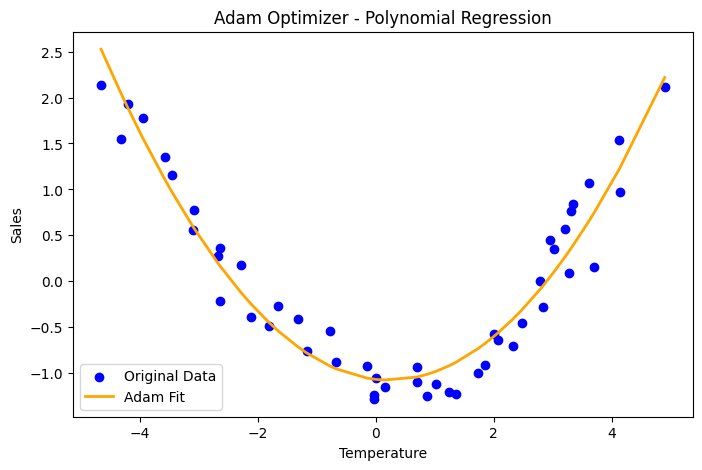

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

data = pd.read_csv('Ice_cream selling data.csv')
X_input = data[['Temperature (°C)']].values
y_target = data['Ice Cream Sales (units)'].values

poly_feat = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_feat.fit_transform(X_input)

X_mean = np.mean(X_poly, axis=0)
X_std = np.std(X_poly, axis=0)
X_poly = (X_poly - X_mean) / X_std

y_mean = np.mean(y_target)
y_std = np.std(y_target)
y_scaled = (y_target - y_mean) / y_std

np.random.seed(42)
weights = np.zeros(X_poly.shape[1])
bias = 0.0

lr = 0.05
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
n_epochs = 500
m_samples = len(y_scaled)

m_w = np.zeros_like(weights)
v_w = np.zeros_like(weights)
m_b = 0.0
v_b = 0.0

for t in range(1, n_epochs + 1):
    y_predicted = np.dot(X_poly, weights) + bias
    err = y_predicted - y_scaled

    grad_w = (1 / m_samples) * np.dot(X_poly.T, err)
    grad_b = (1 / m_samples) * np.sum(err)

    m_w = beta1 * m_w + (1 - beta1) * grad_w
    v_w = beta2 * v_w + (1 - beta2) * (grad_w ** 2)

    m_b = beta1 * m_b + (1 - beta1) * grad_b
    v_b = beta2 * v_b + (1 - beta2) * (grad_b ** 2)

    m_w_corrected = m_w / (1 - beta1 ** t)
    v_w_corrected = v_w / (1 - beta2 ** t)

    m_b_corrected = m_b / (1 - beta1 ** t)
    v_b_corrected = v_b / (1 - beta2 ** t)

    weights = weights - lr * m_w_corrected / (np.sqrt(v_w_corrected) + epsilon)
    bias = bias - lr * m_b_corrected / (np.sqrt(v_b_corrected) + epsilon)

print("Training finished successfully by")

plt.figure(figsize=(8, 5))
plt.scatter(X_input, y_scaled, color='blue', label='Original Data')
y_final_pred = np.dot(X_poly, weights) + bias
sorted_indices = np.argsort(X_input.flatten())
plt.plot(X_input[sorted_indices], y_final_pred[sorted_indices], color='orange', linewidth=2, label='Adam Fit')
plt.xlabel('Temperature')
plt.ylabel('Sales')
plt.title('Adam Optimizer - Polynomial Regression')
plt.legend()
plt.show()